## Model Comparison & Benchmark Results

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Final Model Performance Table (All 4 Metrics for Train & Test)

In [2]:
results_df = pd.read_csv("../results/model_comparison.csv")
display(results_df[[
    'Model', 'Type',
    'Train_MAE', 'Train_MSE', 'Train_RMSE', 'Train_R2',
    'Test_MAE', 'Test_MSE', 'Test_RMSE', 'Test_R2',
    'Fit_Time_sec'
]])

,Model,Type,Train_MAE,Train_MSE,Train_RMSE,Train_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2,Fit_Time_sec
0,xgboost,Ensemble Model,1.6912,5.8255,2.4136,0.9576,2.6448,15.6882,3.9608,0.8816,3.423
1,random_forest,Ensemble Model,1.1181,3.0658,1.7509,0.9777,2.5797,16.0977,4.0122,0.8785,27.812
2,svr_rbf,Base Model (Individual),3.0685,23.4617,4.8437,0.8292,3.2075,24.7279,4.9727,0.8134,33.389
3,decision_tree,Base Model (Individual),2.3018,11.9185,3.4523,0.9132,3.4737,29.0789,5.3925,0.7806,0.234
4,poly_ridge,Base Model (Individual),3.9865,32.2942,5.6828,0.7649,4.0135,32.4453,5.6961,0.7552,2.823
5,ridge,Base Model (Individual),5.7659,65.4695,8.0913,0.5233,5.8985,66.9638,8.1831,0.4947,0.246


### 2. Bar Plot: Test R2 Comparison Across Models

C:\Users\Shlok\AppData\Local\Temp\ipykernel_4296\3079056045.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df.sort_values('Test_R2', ascending=False), x='Test_R2', y='Model', palette='viridis')


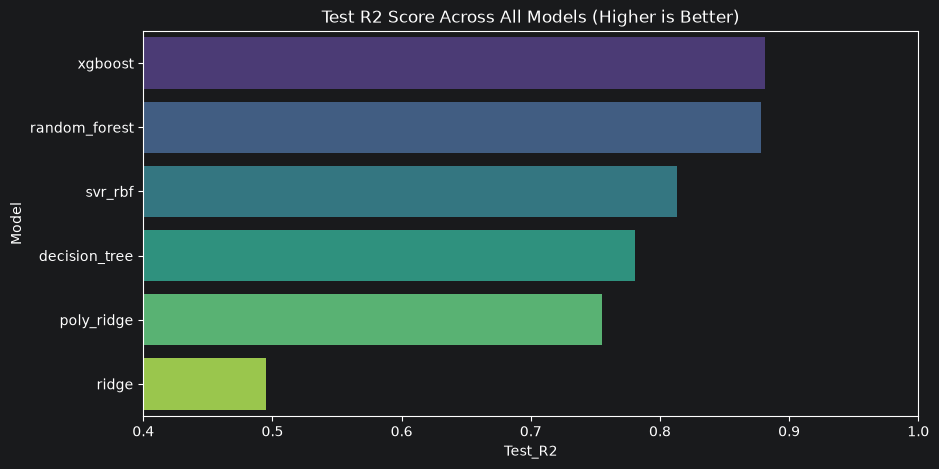

In [3]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df.sort_values('Test_R2', ascending=False), x='Test_R2', y='Model', palette='viridis')
plt.title("Test R2 Score Across All Models (Higher is Better)")
plt.xlim(0.4, 1.0)
plt.show()

### 3. Bar Plot: Test RMSE Comparison Across Models

C:\Users\Shlok\AppData\Local\Temp\ipykernel_4296\3819108375.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df.sort_values('Test_RMSE', ascending=True), x='Test_RMSE', y='Model', palette='mako')


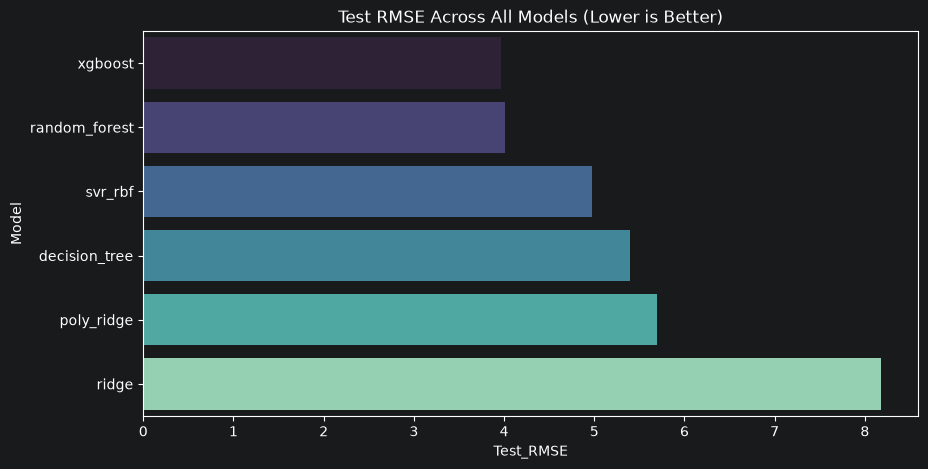

In [4]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df.sort_values('Test_RMSE', ascending=True), x='Test_RMSE', y='Model', palette='mako')
plt.title("Test RMSE Across All Models (Lower is Better)")
plt.show()

### 4. Multi-Seed Stability Summary (5 Random Splits)

In [5]:
rep_df = pd.read_csv("../results/repeated_seed_metrics.csv")
summary = rep_df.groupby("Model").agg({
    'Test_MAE': ['mean', 'std'],
    'Test_MSE': ['mean', 'std'],
    'Test_RMSE': ['mean', 'std'],
    'Test_R2': ['mean', 'std']
}).round(4)
summary

Test_MAE         Test_MSE         Test_RMSE         Test_R2  \
                  mean     std     mean     std      mean     std    mean   
Model                                                                       
decision_tree   3.4977  0.0195  29.6271  0.7460    5.4427  0.0686  0.7790   
poly_ridge      3.9896  0.0475  32.5428  0.6421    5.7044  0.0563  0.7573   
random_forest   2.5851  0.0307  16.5105  0.7111    4.0626  0.0867  0.8768   
ridge           5.8114  0.0807  65.7292  1.2660    8.1070  0.0781  0.5098   
svr_rbf         3.1650  0.0355  24.5328  0.5151    4.9528  0.0518  0.8170   
xgboost         2.6381  0.0233  16.0080  0.4413    4.0007  0.0547  0.8806   

                       
                  std  
Model                  
decision_tree  0.0054  
poly_ridge     0.0059  
random_forest  0.0060  
ridge          0.0092  
svr_rbf        0.0037  
xgboost        0.0041

### 5. Final Key Takeaways:
1. **Linear Model Underfitting**: Ridge achieves R2 ~ 0.495 because straight lines cannot fit exponential thermal combustion kinetics.
2. **Polynomial Feature Expansion**: Adding degree-2 cross-terms in Polynomial Ridge jumps R2 to 0.755 (+26% gain!).
3. **Hyperparameter Tuning Impact**: Tuning improved Decision Tree (+4.5%), SVR (+9.4%), and XGBoost (+2.3%).
4. **Top Performers**: XGBoost achieved the highest overall test accuracy (R2 = 0.8816, RMSE = 3.96 mg/m3), while Random Forest achieved the lowest absolute error (MAE = 2.58 mg/m3).
